In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv


# HEAVY MACHINERY TRANSACTION VALUE PREDICTION 

#### Regression dataset: A regression dataset is a dataset where the target (output) variable is a continuous numerical value.
#### Metric: RMSLE

# Notes for myself:

#### EDA -> Preprocessing -> Feature Engineering -> Model Comparison ->
#### Hyperparameter Tuning (+ early stopping) -> OOF Stacking (3 meta-strategies) -> Submission
#### Early stopping is a technique that automatically stops training a model when its performance on unseen validation data stops improving

####  - NATIVE categorical handling instead of manual encoding for LightGBM and CatBoost:
####      LightGBM  -> pandas 'category' dtype columns, auto-detected internal splits
####      CatBoost  -> raw string columns via cat_features (its ordered target statistics
####                   are usually stronger than any manual target/frequency encoding)

####  - XGBoost's native categorical mode (enable_categorical=True) was tested too, but on
####    this dataset it scored worse.

####  - HistGB and ExtraTrees use an ORDINAL-encoded frame instead of one-hot, which
####    keeps dimensionality low and lets HistGB use its native categorical_features support.

####  - 5-fold OOF (up from 3) for both hyperparameter validation and stacking -> lower-variance,
####    more reliable meta-features -> a more accurate meta-model.

####  - THREE meta-strategies are computed out-of-fold (ElasticNetCV stack, non-negative
####    weighted blend, small LightGBM meta-learner) and whichever scores lowest OOF is used.

In [3]:

# STEP 1 : IMPORT LIBRARIES

# Import all libraries required for data handling,
# visualization, preprocessing, model building,
# evaluation and ensembling.
#
# Each library performs a specific task:
# Pandas -> tables
# NumPy -> mathematics
# Matplotlib/Seaborn -> graphs
# Scikit-Learn -> preprocessing and ML models
# LightGBM/XGBoost/CatBoost -> advanced boosting models

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, time
warnings.filterwarnings('ignore')

from sklearn.model_selection import KFold, train_test_split, RandomizedSearchCV
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.linear_model import Ridge, ElasticNetCV
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_log_error
from scipy.optimize import minimize

import lightgbm as lgb
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

# Display up to 60 columns when printing a Pandas DataFrame without truncating the column view
pd.set_option('display.max_columns', 60)
# Variable here, random_state=42 sets a fixed seed to ensure reproducible random results across runs.
RANDOM_STATE = 42

In [4]:
# STEP 2 : LOAD DATA

# Read the training and testing datasets.

# Training data contains both input features and the target value.

# Testing data contains only input features.

# The model predicts TargetValue for every row in the test dataset.


DATA_DIR = '/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge'
# Read the entire file before inferring data types to avoid mixed-type warnings.
train = pd.read_csv(f'{DATA_DIR}/train.csv', low_memory=False)
test  = pd.read_csv(f'{DATA_DIR}/test.csv',  low_memory=False)

print(f"Train shape: {train.shape} | Test shape: {test.shape}")

# Apply log1p to the target variable to reduce skewness and optimize for the RMSLE evaluation metric.
print("Target column: TargetValue  (RMSLE evaluation -> we model log1p(TargetValue))")

TARGET = 'TargetValue'
ID_COL = 'TransactionID'

Train shape: (138701, 50) | Test shape: (15000, 49)
Target column: TargetValue  (RMSLE evaluation -> we model log1p(TargetValue))


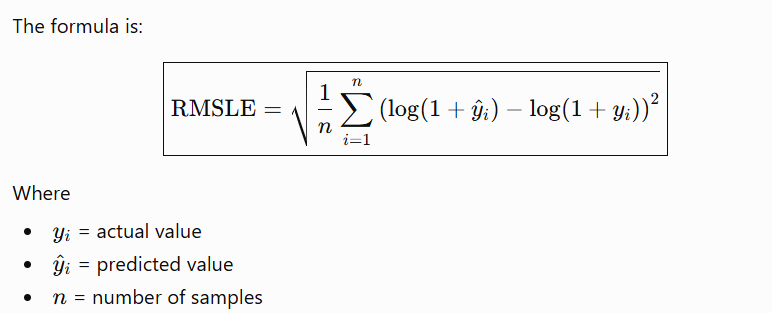


2. EXPLORATORY DATA ANALYSIS

--- dtypes ---
object     44
int64       4
float64     2
Name: count, dtype: int64

--- Missing value % (top 20) ---
col19                 99.952416
col18                 99.952416
col5                  92.515555
col4                  92.515555
col27                 89.214930
col28                 89.214930
col29                 86.393753
col30                 86.393753
col13                 83.125572
col14                 83.125572
col7                  83.125572
col6                  83.125572
col9                  83.125572
col8                  83.125572
col11                 83.125572
col3                  78.909309
Forks                 78.861724
Spec_ReleaseSeries    76.282795
col1                  75.641127
col12                 72.340502
dtype: float64

--- Target summary (univariate) ---
count    138701.000000
mean      41521.874047
std       26361.125948
min        7500.000000
25%       20500.000000
50%       35000.000000
75%       57000.000000

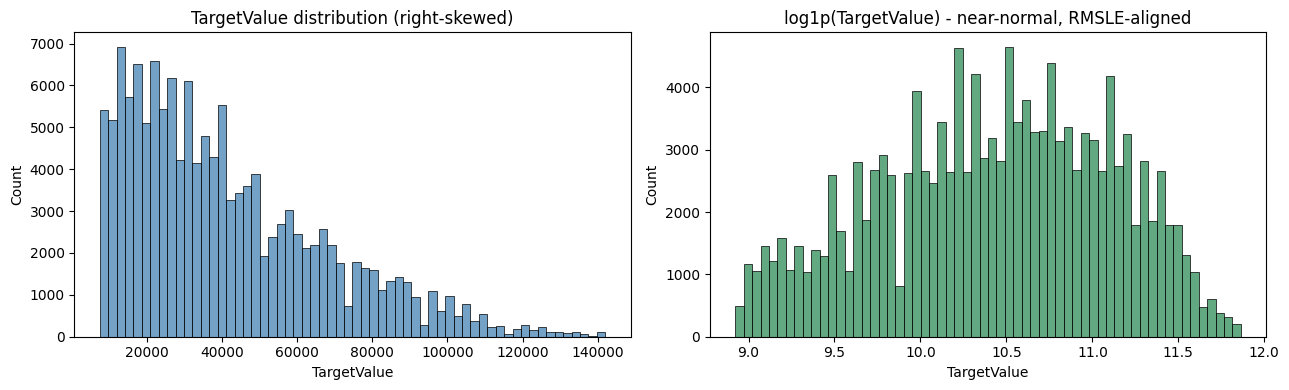

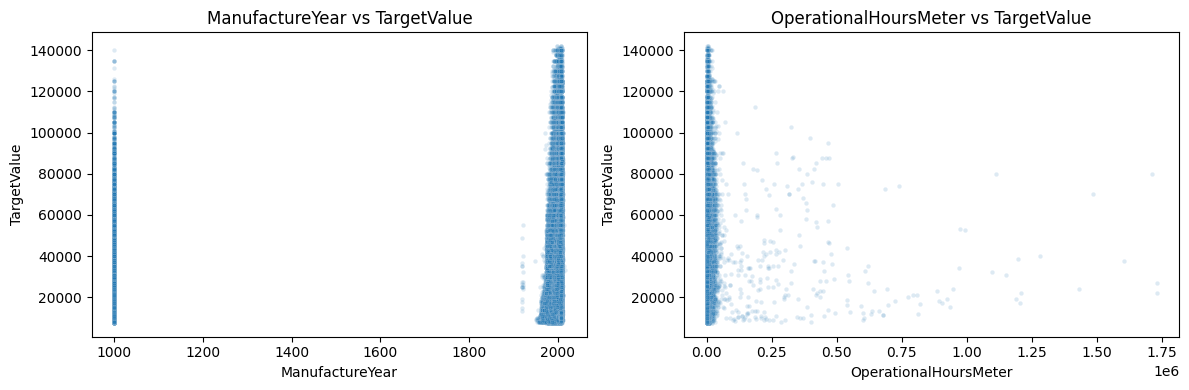

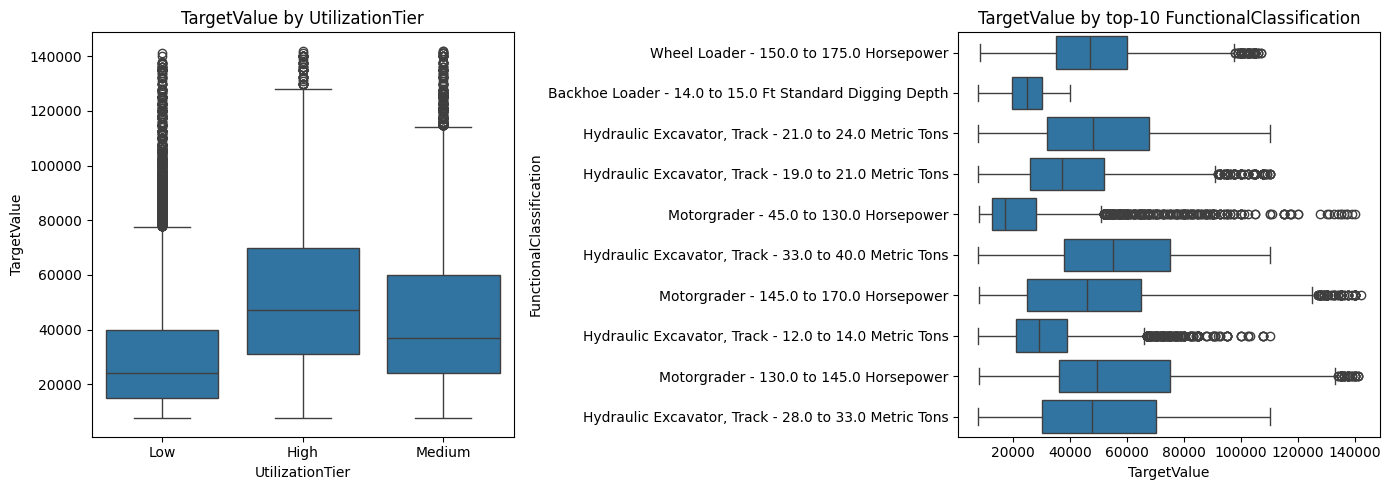


--- Cardinality of object columns (top 15) ---
TransactionDate             3676
Spec_FullDescriptor         3505
Spec_BaseClass              1249
Spec_SubClass                147
Spec_VariantModifier         132
Spec_ReleaseSeries           113
FunctionalClassification      65
RegionCode                    53
VendorPartnerID               31
col22                         27
col21                         18
col15                         15
col10                         11
col27                          9
DrivetrainType                 8
dtype: int64


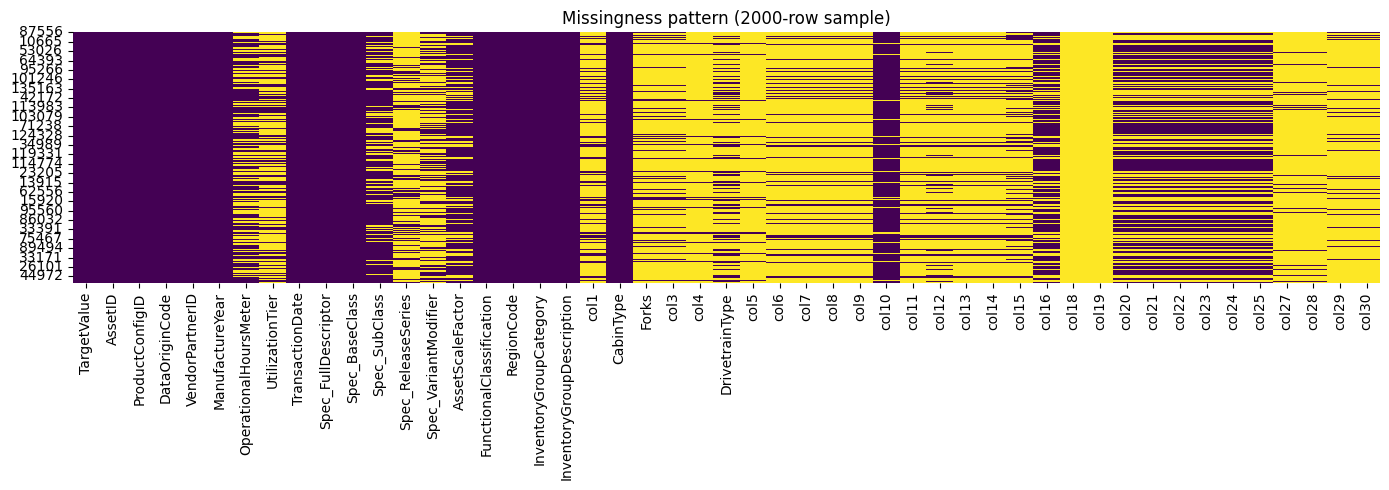

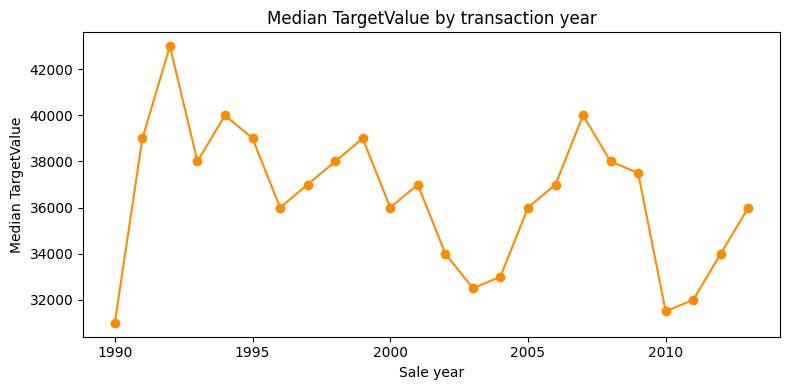


EDA INSIGHTS:
 - TargetValue is right-skewed -> log1p transform makes the loss ~RMSE and matches RMSLE.
 - col18/col19 are ~100% missing -> dropped. Missingness PATTERN across the sparse 'colN'
   spec fields still carries signal (spec_missing_count).
 - ManufactureYear has implausible values (~1001) -> treated as missing, not a true year.
 - High-cardinality identifiers (AssetID, ProductConfigID, Spec_FullDescriptor, ...) are
   now handled NATIVELY by each boosting library instead of manually target-encoded --
   CatBoost's ordered target statistics and LightGBM/XGBoost's native categorical splits
   are generally stronger than any encoding we could build by hand.
 - Joint category effects (e.g. a specific BaseClass x SubClass combination, or
   UtilizationTier x age bucket) are given directly as interaction columns so trees don't
   have to rediscover them from two separate splits.



In [5]:
# STEP 3 : EXPLORATORY DATA ANALYSIS (EDA)

# Understand the dataset before modelling.

# We inspect:
# • Missing values
# • Data types
# • Target distribution - the process of studying the target variable (the value the model is trying to predict) to understand its characteristics before training a model
# • Correlations - how strongly two variables are related and whether they move together
# • Outliers
# • Category frequencies

# This helps us decide what preprocessing and feature engineering should be performed.


print("\n" + "="*90 + "\n2. EXPLORATORY DATA ANALYSIS\n" + "="*90)

# counts how many columns belong to each data type
print("\n--- dtypes ---")
print(train.dtypes.value_counts())

print("\n--- Missing value % (top 20) ---")
miss = train.isna().mean().sort_values(ascending=False) * 100
print(miss.head(20))

print("\n--- Target summary (univariate) ---")
# Desc the target column alone here
print(train[TARGET].describe())


# Create a figure with 1 row and 2 columns for plotting two histograms side by side.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
# Plot the distribution of the original target values.
sns.histplot(train[TARGET], bins=60, ax=axes[0], color='steelblue')
# Add a title explaining that the original target is right-skewed.
axes[0].set_title('TargetValue distribution (right-skewed)')
# Plot the log-transformed target distribution to reduce skewness.
sns.histplot(np.log1p(train[TARGET]), bins=60, ax=axes[1], color='seagreen')
# Add a title indicating that the transformed target is closer to a normal distribution.
# # Large target values produce much larger squared errors, so the model prioritizes reducing those errors over smaller ones to minimize the overall loss.
axes[1].set_title('log1p(TargetValue) - near-normal, RMSLE-aligned')
# Automatically adjust spacing so plots do not overlap.
plt.tight_layout()
# Display both histograms.
plt.show()


# Scatter Plots
# Explore how important numerical features relate to TargetValue.


# Select important numerical features for relationship analysis.
num_candidates = ['ManufactureYear', 'OperationalHoursMeter']
# Create one subplot for each selected numerical feature.
fig, axes = plt.subplots(1, len(num_candidates), figsize=(12, 4))
# Loop through each feature and its corresponding subplot.
for ax, col in zip(axes, num_candidates):
    # Replace zero values with NaN because zeros often represent missing values.
    vals = train[col].replace(0, np.nan)
    # Draw a scatter plot showing the relationship between the feature and TargetValue.
    sns.scatterplot(
        x=vals,
        y=train[TARGET],
        alpha=0.15,      # Make points transparent to reduce overplotting.
        ax=ax,           # subplots on 0 - left, 1 - right
        s=10             # Use small point size since there are many observations.
    )
    # Give the scatter plot an informative title.
    ax.set_title(f'{col} vs TargetValue')
# Automatically adjust spacing.
plt.tight_layout()
# Display the scatter plots.
plt.show()


# Boxplots
# Compare TargetValue across important categorical variables.


# Create two side-by-side boxplots.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Find the 10 most frequent FunctionalClassification categories.
top_fc = train['FunctionalClassification'].value_counts().head(10).index
# Plot TargetValue distribution for each UtilizationTier category.
sns.boxplot(
    data=train,
    x='UtilizationTier',
    y=TARGET,
    ax=axes[0]
)
# Add a title for the UtilizationTier boxplot.
axes[0].set_title('TargetValue by UtilizationTier')
# Plot TargetValue only for the top 10 FunctionalClassification categories.
sns.boxplot(
    data=train[train['FunctionalClassification'].isin(top_fc)],  # # Filter the dataset to include only rows where FunctionalClassification is one of the top 10 most frequent categories - isin() func
    y='FunctionalClassification',
    x=TARGET,
    ax=axes[1]
)
# Add a title for the FunctionalClassification boxplot.
axes[1].set_title('TargetValue by top-10 FunctionalClassification')
# Automatically adjust spacing.
plt.tight_layout()
# Display the boxplots.
plt.show()


# Cardinality Analysis
# Identify categorical columns with many unique values.
# Display the number of unique values (cardinality) in each object (categorical/text) column.

# Print a heading for readability.
print("\n--- Cardinality of object columns (top 15) ---")
# Select all object (text/categorical) columns.
obj_cols = train.select_dtypes(include='object').columns
# Count unique values in each object column, sort in descending order,
# and display the top 15 highest-cardinality columns.
print(
    train[obj_cols]
    .nunique()
    .sort_values(ascending=False)
    .head(15)
)


# Missing Value Analysis
# Visualize where missing values occur in the dataset.
# Analyze how missing values are distributed across columns in the dataset.
# Create a figure for the missing value heatmap.

plt.figure(figsize=(14, 5))
# Draw a heatmap showing missing values in a random sample of 2000 rows.
sns.heatmap(
    # **Remove the ID column** since it is not useful for missing-value analysis.
    train.drop(columns=[ID_COL])
    # Randomly sample 2000 rows to keep the heatmap readable.
    .sample(2000, random_state=RANDOM_STATE)
    # Convert the data into True/False values indicating missingness.
    .isna(),
    # Hide the color bar since only missing/non-missing information is needed.
    cbar=False,
    # Use the Viridis color map for better visualization.
    cmap='viridis'
)
# Add a descriptive title.
plt.title('Missingness pattern (2000-row sample)')
# Automatically adjust spacing.
plt.tight_layout()
# Display the missing-value heatmap.
plt.show()


tmp = train.copy()
# Extract the transaction year from the TransactionDate column and store it as sale_year_tmp.
tmp['sale_year_tmp'] = pd.to_datetime(tmp['TransactionDate'], errors='coerce').dt.year # If a value cannot be converted to a valid date, replace it with NaT (Not a Time) instead of raising an error - errors=coerce
# Group the data by transaction year and calculate the median TargetValue for each year.
yearly = tmp.groupby('sale_year_tmp')[TARGET].median()
plt.figure(figsize=(8, 4))
yearly.plot(marker='o', color='darkorange')
plt.title('Median TargetValue by transaction year')
plt.xlabel('Sale year'); plt.ylabel('Median TargetValue')
plt.tight_layout(); plt.show()


# Data leakage - CatBoost's ordered target statistics is CatBoost's built-in way of converting categorical features into meaningful numerical values using the target variable without causing data leakage.
# # Interaction features combine related categories so the tree can learn their joint effect with a single split instead of multiple separate splits.
print("""
EDA INSIGHTS:
 - TargetValue is right-skewed -> log1p transform makes the loss ~RMSE and matches RMSLE.
 - col18/col19 are ~100% missing -> dropped. Missingness PATTERN across the sparse 'colN'
   spec fields still carries signal (spec_missing_count).
 - ManufactureYear has implausible values (~1001) -> treated as missing, not a true year.
 - High-cardinality identifiers (AssetID, ProductConfigID, Spec_FullDescriptor, ...) are
   now handled NATIVELY by each boosting library instead of manually target-encoded --
   CatBoost's ordered target statistics and LightGBM/XGBoost's native categorical splits
   are generally stronger than any encoding we could build by hand.
 - Joint category effects (e.g. a specific BaseClass x SubClass combination, or
   UtilizationTier x age bucket) are given directly as interaction columns so trees don't
   have to rediscover them from two separate splits.
""")

## **1. TargetValue Distribution (Right-Skewed Histogram)**

#### **Inference:** The TargetValue distribution is **right-skewed**, meaning most machines have relatively low selling prices while only a few machines are very expensive.

#### **How this inference is drawn:** The histogram has **many bars concentrated on the left (lower prices)** and a **long tail extending to the right (higher prices)**.

#### **Inference:** The dataset contains **outliers (very expensive machines)**.

#### **How this inference is drawn:** The histogram extends up to around **₹140,000**, but only a few observations exist in this range.

#### **Inference:** The target should be **log-transformed** before training.

#### **How this inference is drawn:** The heavy right skew indicates that large prices dominate the distribution, so applying `log1p()` reduces skewness and makes model training more stable.

---

## **2. log1p(TargetValue) Distribution**

#### **Inference:** The log-transformed target is much closer to a **normal (bell-shaped) distribution**.

#### **How this inference is drawn:** The histogram is much more **symmetric**, with values spread more evenly around the center.

#### **Inference:** The influence of extremely expensive machines has been reduced.

#### **How this inference is drawn:** The long right tail seen in the original distribution has become much shorter after the logarithmic transformation.

#### **Inference:** The transformed target is suitable for **RMSLE-based regression models**.

#### **How this inference is drawn:** RMSLE is computed in log space, so training on `log1p(TargetValue)` aligns the optimization objective with the evaluation metric.

---

# **3. ManufactureYear vs TargetValue (Scatter Plot)**

#### **Inference:** Most machines were manufactured between approximately **1990 and 2012**.

#### **How this inference is drawn:** Nearly all points are clustered within this year range.

#### **Inference:** The value **1000** is an invalid manufacture year.

#### **How this inference is drawn:** A vertical line of points appears at **1000**, which is not a realistic manufacture year and indicates erroneous or missing data.

#### **Inference:** Newer machines generally tend to have higher selling prices.

#### **How this inference is drawn:** Higher TargetValue points are concentrated among more recent manufacture years, whereas older machines mostly appear at lower prices.

#### **Inference:** ManufactureYear alone does not completely determine price.

#### **How this inference is drawn:** Machines from the same year have a wide spread of prices, indicating that other features also influence the selling price.

---

# **4. OperationalHoursMeter vs TargetValue (Scatter Plot)**

#### **Inference:** Most machines have relatively low operational hours.

#### **How this inference is drawn:** Most observations are densely clustered near zero operational hours.

#### **Inference:** Higher operational hours generally correspond to lower prices.

#### **How this inference is drawn:** Machines with extremely high operational hours are mostly associated with lower TargetValue values.

#### **Inference:** OperationalHoursMeter is highly skewed.

#### **How this inference is drawn:** Most observations lie near zero while only a few extend to very large hour values.

#### **Inference:** Applying a logarithmic transformation to operational hours is beneficial.

#### **How this inference is drawn:** The large positive skew suggests that `log1p(OperationalHoursMeter)` compresses extreme values and produces a more balanced feature.

---

# **5. TargetValue by UtilizationTier (Box Plot)**

#### **Inference:** Machines in the **High** utilization tier generally have the highest median TargetValue.

#### **How this inference is drawn:** The median line inside the High utilization box is positioned above those of the Low and Medium tiers.

#### **Inference:** The selling price distribution differs across utilization tiers.

#### **How this inference is drawn:** The positions of the boxes and medians vary noticeably between Low, Medium, and High categories.

#### **Inference:** All utilization tiers contain price outliers.

#### **How this inference is drawn:** Numerous points lie above the whiskers in each category.

#### **Inference:** UtilizationTier is likely to be a useful predictive feature.

#### **How this inference is drawn:** Different utilization categories exhibit different price distributions.

---

# **6. TargetValue by Top-10 FunctionalClassification (Box Plot)**

#### **Inference:** Different machine types have different price ranges.

#### **How this inference is drawn:** The median and interquartile ranges vary considerably across FunctionalClassification categories.

#### **Inference:** Some machine categories are consistently more expensive than others.

#### **How this inference is drawn:** Certain boxplots are positioned much farther to the right, indicating higher median TargetValues.

#### **Inference:** Every machine type contains price variability.

#### **How this inference is drawn:** Each boxplot has its own spread (IQR) and whiskers.

#### **Inference:** FunctionalClassification is an important categorical feature.

#### **How this inference is drawn:** The price distribution clearly changes depending on the machine classification.

---

# **7. Missingness Pattern Heatmap**

#### **Inference:** Some columns contain very few missing values.

#### **How this inference is drawn:** These columns appear almost entirely in the color representing non-missing values.

#### **Inference:** Several specification columns (`col18`, `col19`, etc.) contain a very high percentage of missing values.

#### **How this inference is drawn:** These columns appear almost entirely in the color representing missing values.

#### **Inference:** Missing values are not randomly distributed.

#### **How this inference is drawn:** Many missing values appear in consistent vertical patterns across specific columns.

#### **Inference:** Missingness itself may carry useful information.

#### **How this inference is drawn:** Since groups of specification fields are simultaneously missing, the number of missing specification values can be engineered into a new feature (`spec_missing_count`).

#### **Inference:** Columns with nearly 100% missing values can be removed.

#### **How this inference is drawn:** Such columns contribute almost no usable information for model training.

---

# **8. Median TargetValue by Transaction Year (Line Plot)**

#### **Inference:** The median selling price changes over time.

#### **How this inference is drawn:** The line rises and falls across different transaction years rather than remaining constant.

#### **Inference:** The highest median prices occur around the early and mid-2000s.

#### **How this inference is drawn:** The line reaches its highest points during these years.

#### **Inference:** Median TargetValue decreases around 2010–2011.

#### **How this inference is drawn:** The line drops noticeably during those transaction years.

#### **Inference:** Transaction year influences machine selling price.

#### **How this inference is drawn:** Since median prices vary across years, temporal information likely contributes to predicting TargetValue, making transaction year a useful feature for feature engineering.


# Data Leakage:

#### Split the data into training and validation sets to keep unseen data separate and prevent data leakage.
train_test_split(...)

#### Apply a log transformation to the target values only; this does not introduce data leakage.
y = np.log1p(train[TARGET])

#### CatBoost computes ordered target statistics using only previously seen training rows, preventing target leakage.
CatBoostRegressor(...)

#### Use validation data only to monitor performance and stop training early; it is never used to fit the model.
early_stopping_rounds=100

#### Perform EDA only on the training dataset to avoid using information from unseen data.
#### (All plots and summaries are generated from train.)

#### Compute frequency encodings from the training data only and apply the learned mapping to validation/test data to prevent leakage.
add_frequency_features(train_df, test_df)

New engineered features: ['sale_month_sin', 'sale_month_cos', 'sale_dow_sin', 'sale_dow_cos', 'machine_age', 'age_bucket', 'log_hours', 'hours_per_year', 'hours_age_interaction', 'hours_missing', 'spec_missing_count', 'combo_base_sub', 'combo_func_region', 'combo_util_age', 'AssetID_freq', 'ProductConfigID_freq', 'Spec_FullDescriptor_freq', 'Spec_BaseClass_freq', 'Spec_SubClass_freq', 'Spec_VariantModifier_freq', 'Spec_ReleaseSeries_freq', 'VendorPartnerID_freq', 'RegionCode_freq']

Correlation of engineered numeric features with log1p(TargetValue):
machine_age                 -0.372822
Spec_BaseClass_freq          0.336093
Spec_VariantModifier_freq    0.272335
ProductConfigID_freq         0.239893
Spec_FullDescriptor_freq     0.238723
Spec_SubClass_freq           0.202229
Spec_ReleaseSeries_freq      0.133920
RegionCode_freq              0.066171
VendorPartnerID_freq         0.059222
hours_per_year               0.038551
sale_dow_cos                -0.035110
sale_dow_sin              

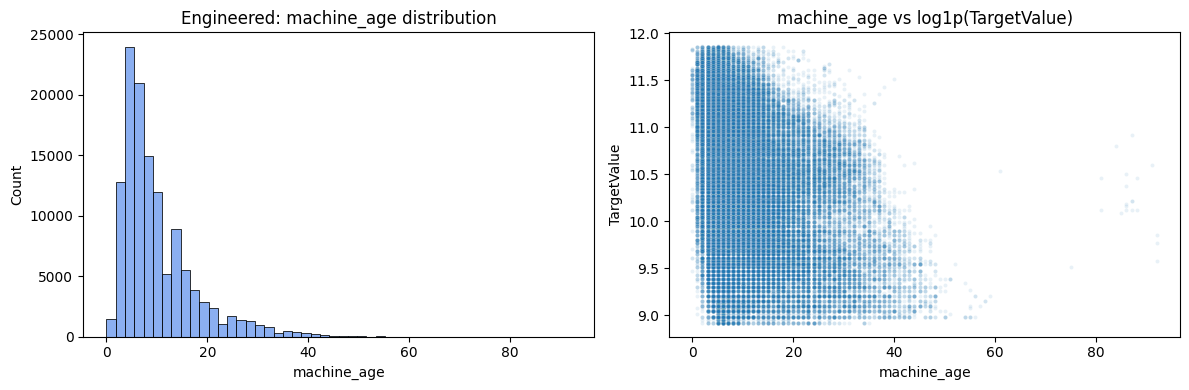

In [6]:
# STEP 4 : FEATURE ENGINEERING

# Create new meaningful features from existing columns.

# Examples:
# Machine Age
# Sale Month
# Sale Day
# Hours Per Year
# Interaction Features
# Missing Value Count

# Better features usually improve prediction more than simply changing the ML model.


def engineer_features(df):
    # Convert TransactionDate to datetime and extract year, month, and day-of-week features.
    df = df.copy()
    df['TransactionDate'] = pd.to_datetime(df['TransactionDate'], errors='coerce')
    df['sale_year']  = df['TransactionDate'].dt.year
    df['sale_month'] = df['TransactionDate'].dt.month
    df['sale_dow']   = df['TransactionDate'].dt.dayofweek

    # Encode cyclical time features (month and day of week) using sine and cosine to preserve their circular nature.
    # If December and January have similar prices because they're both in the same season, a linear model struggles to learn that relationship from raw month numbers.
    df['sale_month_sin'] = np.sin(2 * np.pi * df['sale_month'] / 12) # December and Jan is close (Just 1 month apart)
    df['sale_month_cos'] = np.cos(2 * np.pi * df['sale_month'] / 12) 
    df['sale_dow_sin']   = np.sin(2 * np.pi * df['sale_dow'] / 7)  # Sunday and monday is close
    df['sale_dow_cos']   = np.cos(2 * np.pi * df['sale_dow'] / 7)

    # Clean invalid manufacture years and calculate machine age, replacing impossible ages with NaN.
    df.loc[df['ManufactureYear'] < 1900, 'ManufactureYear'] = np.nan
    df['machine_age'] = df['sale_year'] - df['ManufactureYear']
    df.loc[df['machine_age'] < 0, 'machine_age'] = np.nan

    # Group machine ages into categorical age buckets for better pattern learning.
    df['age_bucket'] = pd.cut(
        df['machine_age'], bins=[-1, 3, 7, 12, 18, 25, 100], # Intervals [-1,3] (0-3); [3,7] (4-7)
        labels=['0-3', '4-7', '8-12', '13-18', '19-25', '25+']
    ).astype(str)

    # Create operational hour-based features, including log transformation and age interaction.
    df['log_hours'] = np.log1p(df['OperationalHoursMeter'])
    df['hours_per_year'] = df['OperationalHoursMeter'] / df['machine_age'].replace(0, np.nan)
    df['hours_missing']  = df['OperationalHoursMeter'].isna().astype(int)
    df['hours_age_interaction'] = df['hours_per_year'] * df['machine_age']

    # Count missing specification fields because the overall missingness pattern itself may help predict the machine's selling price - Machines with more missing specifications(cols) tend to have lower prices.
    # Identify all sparse specification columns whose names start with 'col' - missing values are more
    sparse_spec_cols = [c for c in df.columns if c.startswith('col')] #row-wise
    # Count the number of missing specification values in each row as a new feature.
    df['spec_missing_count'] = df[sparse_spec_cols].isna().sum(axis=1)

    # Drop the original TransactionDate column after extracting all required date-based features.
    df.drop(columns=['TransactionDate'], inplace=True)

    # Replace missing IDs with -1, convert them to integers, and then to strings so they are treated as categorical features.
    for c in ['AssetID', 'ProductConfigID']:
        df[c] = df[c].fillna(-1).astype(int).astype(str)

    # Interaction categoricals: joint category combinations trees would otherwise have to rediscover via two separate splits -> handed to them directly.
    def combo(a, b):
        return df[a].astype(str).fillna('NA') + '_x_' + df[b].astype(str).fillna('NA') # formatting _x_ so it is readable

    df['combo_base_sub']    = combo('Spec_BaseClass', 'Spec_SubClass')
    df['combo_func_region'] = combo('FunctionalClassification', 'RegionCode')
    df['combo_util_age']    = combo('UtilizationTier', 'age_bucket')

    return df

# the model expects the same features during both training and testing so as the i/p features is the same
train_fe = engineer_features(train)
test_fe  = engineer_features(test)

FREQ_COLS = ['AssetID', 'ProductConfigID', 'Spec_FullDescriptor', 'Spec_BaseClass',
             'Spec_SubClass', 'Spec_VariantModifier', 'Spec_ReleaseSeries',
             'VendorPartnerID', 'RegionCode']  # These columns were chosen because they are high-cardinality categorical features

# Create frequency-encoded features by replacing each category with how often it appears in the training data.
def add_frequency_features(train_df, test_df, cols):
    for c in cols:
        freq_map = train_df[c].value_counts(normalize=True) # normalize=True converts counts into proportions (frequencies) instead of raw counts i.e /total freq
        train_df[f'{c}_freq'] = train_df[c].map(freq_map).fillna(0.0)
        test_df[f'{c}_freq']  = test_df[c].map(freq_map).fillna(0.0)
    return train_df, test_df

train_fe, test_fe = add_frequency_features(train_fe, test_fe, FREQ_COLS) # Prevents data leakage # new numerical features(freq) are created from categorical columns before fitting the models

engineered = ['sale_month_sin', 'sale_month_cos', 'sale_dow_sin', 'sale_dow_cos',
              'machine_age', 'age_bucket', 'log_hours', 'hours_per_year',
              'hours_age_interaction', 'hours_missing', 'spec_missing_count',
              'combo_base_sub', 'combo_func_region', 'combo_util_age'] + \
             [f'{c}_freq' for c in FREQ_COLS]
print("New engineered features:", engineered)
# all the new and old features are passed on to each model and the model decides which one is useful

# Compute and display the correlation of engineered numeric features with the log-transformed target variable.
corr_num = [c for c in engineered if pd.api.types.is_numeric_dtype(train_fe[c])]
corrs = train_fe[corr_num].assign(log_target=np.log1p(train_fe[TARGET])) \
    .corr()['log_target'].drop('log_target').sort_values(key=abs, ascending=False)
print("\nCorrelation of engineered numeric features with log1p(TargetValue):")
print(corrs)
# eg: As machine age increases, the selling price generally decreases (neg relationship)

# Visualize the distribution of machine age and its relationship with the log-transformed target.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train_fe['machine_age'].dropna(), bins=50, ax=axes[0], color='cornflowerblue')
axes[0].set_title('Engineered: machine_age distribution')
sns.scatterplot(x=train_fe['machine_age'], y=np.log1p(train_fe[TARGET]),
                 alpha=0.1, s=8, ax=axes[1])
axes[1].set_title('machine_age vs log1p(TargetValue)')
plt.tight_layout(); plt.show()

# **1. Engineered: Machine Age Distribution (Histogram)**

#### **Inference:** Most machines are relatively young, with ages concentrated between approximately **3 and 15 years**.

#### **How this inference is drawn:** The tallest bars in the histogram occur within this age range, indicating that most observations fall there.

#### **Inference:** The machine age distribution is **right-skewed**.

#### **How this inference is drawn:** Most observations are clustered at lower ages, while a long tail extends toward older machines (up to around 90 years).

#### **Inference:** Very old machines are rare.

#### **How this inference is drawn:** The bars become progressively shorter as machine age increases, showing fewer observations.

#### **Inference:** Machine age is likely to be an informative feature for predicting price.

#### **How this inference is drawn:** Since there is substantial variation in machine ages across the dataset, the model can learn different pricing patterns for newer and older machines.

---

# **2. Machine Age vs log1p(TargetValue) (Scatter Plot)**

#### **Inference:** There is a **negative relationship** between machine age and selling price.

#### **How this inference is drawn:** As machine age increases along the x-axis, the highest values of `log1p(TargetValue)` generally decrease.

#### **Inference:** Newer machines have the potential to achieve the highest selling prices.

#### **How this inference is drawn:** The highest points on the y-axis are concentrated at lower machine ages.

#### **Inference:** Older machines generally sell for lower prices.

#### **How this inference is drawn:** Most observations for larger machine ages are located in the lower portion of the plot.

#### **Inference:** Machine age alone does not completely determine the selling price.

#### **How this inference is drawn:** Machines with the same age exhibit a wide range of `log1p(TargetValue)` values, indicating that other features (such as operational hours, specifications, utilization tier, etc.) also influence the price.

#### **Inference:** The relationship is not perfectly linear.

#### **How this inference is drawn:** The scatter forms a broad downward trend rather than a straight line, suggesting tree-based models can capture the relationship more effectively than a simple linear model.

#### **Inference:** `machine_age` is a strong engineered feature.

#### **How this inference is drawn:** The clear downward trend matches its relatively high negative correlation with the target (approximately **-0.37**), making it one of the most informative engineered features in the dataset.


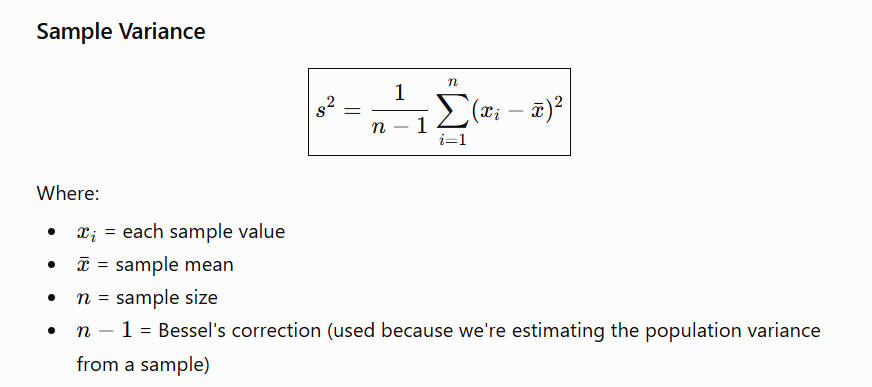

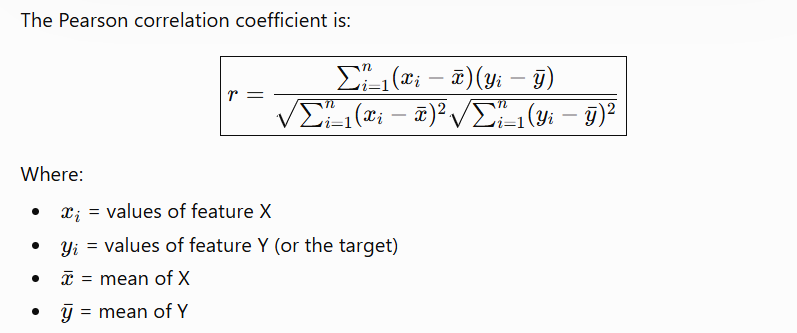

#### **Label Encoding** – Assigns a unique integer (e.g., A→0, B→1) to each category; simple but may incorrectly imply an order between categories.

#### **Ordinal Encoding** – Similar to Label Encoding but designed to handle unseen categories safely; ideal for tree-based models like XGBoost, ExtraTrees, and HistGradientBoosting that require numeric inputs.

#### **One-Hot Encoding** – Creates a separate binary (0/1) column for every unique category, avoiding any artificial ordering but greatly increasing the number of features for high-cardinality data.

#### **Frequency Encoding** – Replaces each category with its frequency (or proportion) in the training data, giving the model information about how common or rare each category is while using only one numeric column.

#### **Target Encoding** – Replaces each category with the average target value for that category, making it highly informative but prone to data leakage if not computed carefully.

#### **CatBoost Encoding (Ordered Target Statistics)** – CatBoost automatically converts categorical values into numerical representations during training using ordered target statistics, reducing data leakage and eliminating the need for manual encoding.


In [7]:
# STEP 5 : PREPROCESSING

# Convert raw data into the format expected by each machine learning algorithm.
# Since different models process categorical variables differently, three separate feature representations are created.


# Print a section heading to clearly separate the preprocessing stage.
print("\n" + "="*90 + "\n4. PREPROCESSING\n" + "="*90)
# Specify columns that should not be used as input features - empty
drop_cols = [ID_COL, TARGET, 'col18', 'col19'] 
# Create a list of feature columns by excluding the dropped columns.
feature_cols = [c for c in train_fe.columns if c not in drop_cols]
# Select all numerical feature columns (integer and float types).
num_cols = train_fe[feature_cols].select_dtypes(include=[np.number]).columns.tolist()
# Select all remaining columns as categorical features.
cat_cols = [c for c in feature_cols if c not in num_cols]
# Print the number of numerical and categorical features.
print(f"Numeric cols: {len(num_cols)} | Categorical cols: {len(cat_cols)}")
# Create the final *training feature matrix* by selecting only feature columns.
X_raw = train_fe[feature_cols].copy()
# Create the final *test feature matrix* using the same feature columns.
X_test_raw = test_fe[feature_cols].copy()

# Apply log1p transformation to the target variable.
# The models will predict log(TargetValue + 1) instead of the original TargetValue.
# This reduces right-skewness, stabilizes variance(how much val in that col spread), and makes the optimization
# objective equivalent to minimizing RMSLE after predictions are converted back.
y = np.log1p(train_fe[TARGET])      # Train models in log-space (RMSE on logs = RMSLE on original values)

# --- Representation A: pandas 'category' dtype -> LightGBM & XGBoost native splits ---

def make_category_frame(train_df, test_df, cat_cols):

    # Create copies of the train and test data so the originals remain unchanged.
    tr, te = train_df.copy(), test_df.copy()
    # Loop through every categorical column.
    for c in cat_cols:
        # Extract all unique categories from the training data.
        # Convert values to strings and replace missing values with "MISSING".
        cats = pd.Index(
            tr[c]
            .astype(str)
            .fillna('MISSING')
            .unique()
        )
        # Convert the training column into pandas Categorical type
        # using the categories learned from the training data.
        tr[c] = pd.Categorical(
            tr[c].astype(str).fillna('MISSING'),
            categories=cats
        )
        # Convert the test column into pandas Categorical type
        # using exactly the same categories as the training data.
        te[c] = pd.Categorical(
            te[c].astype(str).fillna('MISSING'),
            categories=cats
        )
    # Return the processed train and test dataframes.
    return tr, te

X_cat_native, X_cat_native_test = make_category_frame(X_raw, X_test_raw, cat_cols)

# --- Representation B: raw strings -> CatBoost (its own ordered target encoding) ---

# Create copies of the training and test feature sets so the originals are unchanged.
X_str_native, X_str_native_test = X_raw.copy(), X_test_raw.copy()
# Loop through every categorical feature.
for c in cat_cols:
    # Convert the training column to string and replace missing values with "MISSING".
    X_str_native[c] = X_str_native[c].astype(str).fillna('MISSING')
    # Convert the test column to string and replace missing values with "MISSING".
    X_str_native_test[c] = X_str_native_test[c].astype(str).fillna('MISSING')

# --- Representation C: ordinal-encoded categoricals + imputed numerics -> ExtraTrees & HistGB ---

# Create an OrdinalEncoder to convert categorical values into integers.
# Unknown categories in the test set will be encoded as -1.
ord_enc = OrdinalEncoder(
    handle_unknown='use_encoded_value',
    unknown_value=-1
)
# Create a SimpleImputer to replace missing numerical values with the median.
num_imputer = SimpleImputer(strategy='median')


# -- Encode categorical features using Ordinal Encoding.
# Fit the encoder on the training categorical data and transform it into integers.
X_ord_cat = pd.DataFrame(
    ord_enc.fit_transform(  # Learn the mapping and immediately apply it - fit (find unique categoricals and map to num)
        X_raw[cat_cols].astype(str).fillna('MISSING') # astype() Converts every value to a string.
    ),
    columns=cat_cols, # Restores the original column names - col names would be 0, 1, 2... without this
    index=X_raw.index
)
# Transform the test categorical data using the same encoder learned from training.
X_test_ord_cat = pd.DataFrame(
    ord_enc.transform(
        X_test_raw[cat_cols].astype(str).fillna('MISSING')
    ),
    columns=cat_cols,
    index=X_test_raw.index # Keep the original row identifiers so every encoded row still refers to the same machine as in the original dataset.
)


# -- Handle missing values in numerical features.
# Learn the median of each numerical column from the training data
# and replace missing values with those medians.
X_num_imp = pd.DataFrame(
    num_imputer.fit_transform(X_raw[num_cols]), # num_imputer is median (refer above lines)
    columns=num_cols,
    index=X_raw.index
)
# Replace missing values in the test data using the medians learned
# from the training data.
X_test_num_imp = pd.DataFrame(
    num_imputer.transform(X_test_raw[num_cols]),
    columns=num_cols,
    index=X_test_raw.index
)

# -- Standardize numerical features.
# Create a StandardScaler to normalize numerical features.
# (orginal val - mean) / std dev
scaler = StandardScaler()

# Learn the mean and standard deviation from the training data
# and scale the numerical features.
X_num_scaled = pd.DataFrame(
    scaler.fit_transform(X_num_imp),
    columns=num_cols,
    index=X_raw.index
)
# Scale the test numerical features using the same statistics
# learned from the training data.
X_test_num_scaled = pd.DataFrame(
    scaler.transform(X_test_num_imp),
    columns=num_cols,
    index=X_test_raw.index
)

# -- Combine the processed numerical and categorical features.
# Merge scaled numerical features with ordinal-encoded categorical features
# to create the final training dataset.
X_ordinal = pd.concat(
    [X_num_scaled, X_ord_cat],
    axis=1
)[num_cols + cat_cols]
# Merge scaled numerical features with ordinal-encoded categorical features
# to create the final test dataset.
X_ordinal_test = pd.concat(
    [X_test_num_scaled, X_test_ord_cat],
    axis=1
)[num_cols + cat_cols]

# HistGradientBoostingRegressor requires categorical cardinality <= 255. High-cardinality
# columns (AssetID, ProductConfigID, Spec_FullDescriptor, ...) still ride along as plain
# ordinal-coded numeric features -> just not flagged as "categorical" splits for HGB.
cat_card = X_raw[cat_cols].nunique() # returns unique characters
hgb_cat_cols = [c for c in cat_cols if cat_card[c] <= 255] # for hgb
cat_feature_mask = [c in hgb_cat_cols for c in X_ordinal.columns] # bool val - shows which cols are categorical

print(f"Category-dtype frame: {X_cat_native.shape} | String frame: {X_str_native.shape} "
      f"| Ordinal frame: {X_ordinal.shape}")


4. PREPROCESSING
Numeric cols: 24 | Categorical cols: 47
Category-dtype frame: (138701, 71) | String frame: (138701, 71) | Ordinal frame: (138701, 71)


# #### Ridge Regression

## #### 1.3 Why is Ridge Regression used?

#### It serves as a simple linear baseline to measure how much of the prediction problem can be explained using only linear relationships.

#### It is extremely fast to train and provides a benchmark that more complex models should outperform.

#### It reduces overfitting by penalizing very large coefficients through L2 regularization.


## #### 1.4 Why were these parameters chosen?

#### `alpha=5.0` adds moderate L2 regularization, preventing overly large coefficients while still allowing the model to fit the data.

#### `random_state=42` ensures reproducible results whenever randomness is involved.


## #### 1.5 Mathematics and what happens internally

#### **Data:** Uses the ordinal-encoded feature matrix (`X_ordinal`) and the log-transformed target (`log1p(TargetValue)`).

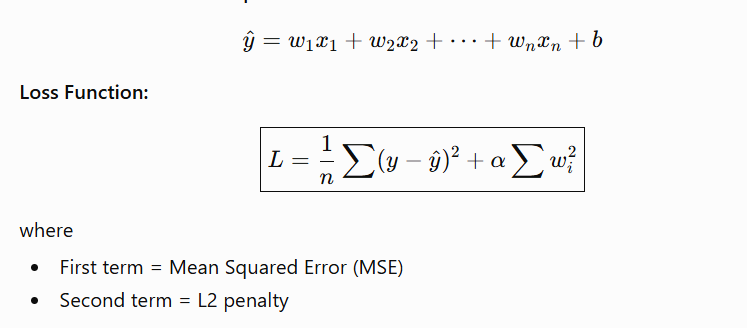

#### The L2 penalty shrinks coefficients towards zero to reduce overfitting.

#### **Optimization:** Solves for the coefficients that minimize the above loss using numerical linear algebra.

#### **Evaluation:** Validation predictions are converted back using `expm1()` and evaluated using RMSLE.

---

# #### ExtraTrees Regressor

## #### 1.3 Why is ExtraTrees used?

#### It captures highly non-linear relationships between features and the target.

#### It naturally models feature interactions without requiring manual feature engineering.

#### Randomized splits reduce variance and improve generalization.

---

## #### 1.4 Why were these parameters chosen?

#### `n_estimators=300` builds 300 trees, making predictions more stable.

#### `max_depth=18` limits tree depth to prevent overfitting.

#### `n_jobs=-1` uses all CPU cores to speed up training.

#### `random_state=42` ensures reproducible random splits.

---

## #### 1.5 Mathematics and what happens internally

#### **Data:** Uses the ordinal-encoded feature matrix.

#### **Model:** Creates hundreds of independent decision trees.

#### Each tree randomly selects features and random split points.

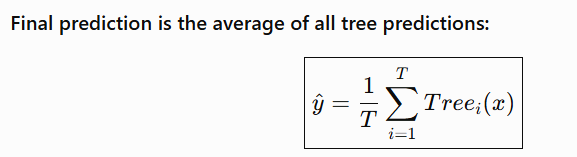

#### **Loss Function:** Each tree minimizes Mean Squared Error during splitting.

#### **Optimization:** Trees are grown independently using randomization (no gradient optimization).

#### **Evaluation:** RMSLE on the validation set.

---

# #### HistGradientBoosting Regressor

## #### 1.3 Why is HistGradientBoosting used?

#### It is much faster than traditional Gradient Boosting on large datasets.

#### It supports native categorical features.

#### Histogram binning significantly reduces computation.

#### Early stopping automatically prevents overfitting.

---

## #### 1.4 Why were these parameters chosen?

#### `max_iter=400` allows the model to build up to 400 boosting trees.

#### `learning_rate=0.07` makes learning gradual and stable.

#### `max_depth=8` limits tree complexity.

#### `categorical_features=cat_feature_mask` tells HGB which columns are categorical.

#### `early_stopping=True` stops training if validation performance stops improving.

#### `n_iter_no_change=20` waits 20 rounds before stopping.

#### `validation_fraction=0.1` reserves 10% of the training data for early stopping.

---

## #### 1.5 Mathematics and what happens internally

#### **Data:** Uses ordinal-encoded features with selected columns treated as categorical.

#### **Model:** Builds one tree after another.

#### Each new tree learns the residual errors made by previous trees.

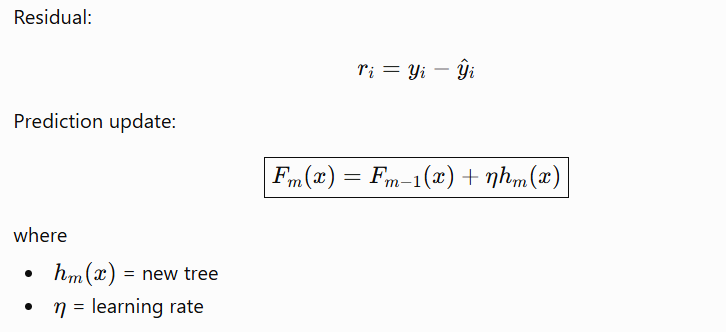

#### **Loss Function:** Squared Error.

#### **Optimization:** Gradient Boosting using first-order gradients.

#### **Evaluation:** RMSLE.

---

# #### LightGBM

## #### 1.3 Why is LightGBM used?

#### It is one of the fastest gradient boosting libraries for structured/tabular datasets.

#### It handles categorical features natively.

#### It grows trees leaf-wise, usually producing higher accuracy.

#### It scales efficiently to very large datasets.

---

## #### 1.4 Why were these parameters chosen?

#### `n_estimators=400` builds enough trees for good accuracy.

#### `learning_rate=0.07` provides gradual learning.

#### `num_leaves=63` controls tree complexity.

#### `subsample=0.8` trains each tree on 80% of the rows to reduce overfitting.

#### `colsample_bytree=0.8` uses only 80% of the features for each tree.

#### `verbose=-1` suppresses training logs.

#### `random_state=42` ensures reproducibility.

---

## #### 1.5 Mathematics and what happens internally

#### **Data:** Uses category-dtype features.

#### **Model:** Gradient Boosting with leaf-wise tree growth.

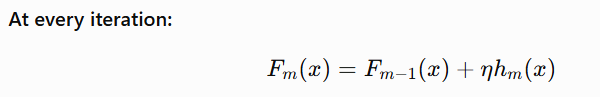

#### Leaf-wise growth chooses the leaf that gives the maximum reduction in loss.

#### **Loss Function:** Mean Squared Error.

#### **Optimization:** Gradient Descent in function space using decision trees.

#### **Evaluation:** RMSLE.

---

# #### XGBoost

## #### 1.3 Why is XGBoost used?

#### It is one of the highest-performing algorithms for structured datasets.

#### It includes regularization to reduce overfitting.

#### Histogram-based tree construction makes training efficient.

#### It handles complex feature interactions extremely well.

---

## #### 1.4 Why were these parameters chosen?

#### `n_estimators=400` builds sufficient boosting rounds.

#### `learning_rate=0.07` allows gradual improvement.

#### `max_depth=8` balances underfitting and overfitting.

#### `subsample=0.8` randomly samples rows for each tree.

#### `colsample_bytree=0.8` randomly samples features for each tree.

#### `tree_method='hist'` speeds up tree construction using histogram bins.

#### `random_state=42` ensures reproducibility.

---

## #### 1.5 Mathematics and what happens internally

#### **Data:** Uses ordinal-encoded features.

#### **Model:** Sequential Gradient Boosting.

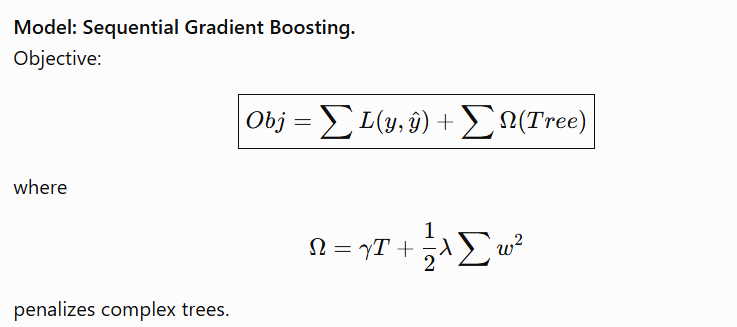

#### Every new tree fits the residual gradients.

#### **Loss Function:** Squared Error + Regularization.

#### **Optimization:** Second-order Gradient Boosting using first and second derivatives.

#### **Evaluation:** RMSLE.

---

# #### CatBoost

## #### 1.3 Why is CatBoost used?

#### It is specifically designed for datasets containing many categorical features.

#### It automatically performs ordered target encoding without data leakage.

#### It requires almost no manual preprocessing.

#### It usually performs extremely well on mixed numerical and categorical datasets.

---

## #### 1.4 Why were these parameters chosen?

#### `iterations=400` builds 400 boosting trees.

#### `learning_rate=0.07` allows stable learning.

#### `depth=8` captures complex interactions while reducing overfitting.

#### `verbose=False` suppresses training logs.

#### `random_state=42` ensures reproducible training.

---

## #### 1.5 Mathematics and what happens internally

#### **Data:** Uses raw string categorical features.

#### **Model:** Gradient Boosting with ordered target statistics.

#### Categories are converted into numerical values during training using only previous observations, preventing target leakage.

#### Prediction update:

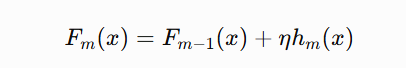

#### **Loss Function:** Squared Error.

#### **Optimization:** Gradient Boosting with ordered boosting and ordered target statistics.

#### **Evaluation:** RMSLE.


In [8]:
# STEP 6 : MODEL COMPARISON

# Train several different regression models using default settings.
# Compare their validation performance to identify which algorithms are strongest before hyperparameter tuning.

print("\n" + "="*90 + "\n5. MODEL COMPARISON (80/20 holdout)\n" + "="*90)

def rmsle_from_log_preds(y_true_log, y_pred_log):
    # Convert the true target values from log-space back to their original scale.
    y_true = np.expm1(y_true_log)
    # Convert predicted values back to the original scale and clip negatives to zero.
    y_pred = np.clip(np.expm1(y_pred_log), 0, None)
    # Calculate and return the Root Mean Squared Logarithmic Error (RMSLE).
    return np.sqrt(mean_squared_log_error(y_true, y_pred))

# Split the row indices into training and validation sets - A validation set is a portion of the training data that is not used to train the model, but is used to evaluate the model's performance and tune its parameters.
idx_tr, idx_val = train_test_split(np.arange(len(X_raw)), test_size=0.2, random_state=RANDOM_STATE) # arrange 0 - say 12190 then randomly split 

def eval_holdout(name, model, X_source, fit_kwargs=None):
    # Record the starting time to measure training duration.
    t0 = time.time()
    # Select the training features.
    # Works for both pandas DataFrames and NumPy arrays.
    # iloc - select rows(here) and columns by their integer position (index number)
    Xtr = X_source.iloc[idx_tr] if isinstance(X_source, pd.DataFrame) else X_source[idx_tr]
    # Select the validation features.
    Xva = X_source.iloc[idx_val] if isinstance(X_source, pd.DataFrame) else X_source[idx_val]
    # Create a fresh copy of the model so the original model remains unchanged.
    m = clone(model)
    # Train the model using the training data.
    # fit_kwargs allows passing optional parameters (e.g., categorical features).
    m.fit(
        Xtr,
        y.iloc[idx_tr],
        **(fit_kwargs or {})
    )
    # Predict on the validation set and calculate RMSLE.
    score = rmsle_from_log_preds(
        y.iloc[idx_val].values,
        m.predict(Xva)
    )
    # Print the model name, validation RMSLE, and total training time.
    print(
        f"{name:28s} | holdout RMSLE={score:.4f} | {time.time()-t0:.1f}s"
    )
    # Return the RMSLE score.
    return score

# Evaluate Ridge Regression as a simple linear baseline to check how much of the problem can be 
# explained using linear relationships (alpha=5.0(formula) adds L2 regularization to reduce overfitting and improve generalization).
eval_holdout('Ridge (linear, ordinal)', Ridge(alpha=5.0, random_state=RANDOM_STATE), X_ordinal)

# Evaluate Extra Trees because it captures complex non-linear relationships and feature interactions with low variance 
# (300 trees improve stability, max_depth=18 controls overfitting, n_jobs=-1 uses all CPU cores).
eval_holdout('ExtraTrees (ordinal)', ExtraTreesRegressor(n_estimators=300, max_depth=18, n_jobs=-1,
                                                          random_state=RANDOM_STATE), X_ordinal)

# Evaluate Histogram Gradient Boosting because it is a fast boosting algorithm that supports native categorical features and early stopping (400 boosting rounds, 
# learning_rate=0.07 balances learning speed, max_depth=8 limits tree complexity, early stopping avoids overfitting).
# Yes, HistGradientBoostingRegressor (HGB) is a boosting algorithm, meaning it builds trees one after another, where each new tree tries to correct the mistakes (residuals) made by the previous trees
eval_holdout('HistGB (native cat, ordinal)',
             HistGradientBoostingRegressor(max_iter=400, learning_rate=0.07, max_depth=8,
                                            categorical_features=cat_feature_mask,
                                            random_state=RANDOM_STATE, early_stopping=True,  # validation metric (loss) - error
                                            n_iter_no_change=20, validation_fraction=0.1), - # If the validation score doesn't improve for 20 consecutive boosting iterations, training stops, automatically reserves 10% of the training data as an internal validation set for early stopping.
             X_ordinal) # contains all

# Evaluate LightGBM because it is one of the fastest and most accurate gradient boosting libraries for structured/tabular data 
# (400 trees provide sufficient learning, learning_rate=0.07 gives smoother learning, num_leaves=63 controls model complexity, 
# subsample and colsample_bytree=0.8 reduce overfitting).
eval_holdout('LightGBM (native categorical)',
             LGBMRegressor(n_estimators=400, learning_rate=0.07, num_leaves=63, # Each tree can have at most 63 leaf nodes
                            subsample=0.8, colsample_bytree=0.8, # no memorization - only 80% of feature everytime
                            random_state=RANDOM_STATE, verbose=-1),
             X_cat_native)

# Evaluate XGBoost because it is a highly optimized gradient boosting algorithm that performs exceptionally well on tabular datasets 
# (400 trees, learning_rate=0.07 for gradual learning, max_depth=8 balances bias and variance, 
# histogram tree method speeds up training, subsampling improves generalization).
eval_holdout('XGBoost (ordinal)',
             XGBRegressor(n_estimators=400, learning_rate=0.07, max_depth=8,
                           subsample=0.8, colsample_bytree=0.8, # randomly use only 80% of the training rows
                           tree_method='hist', random_state=RANDOM_STATE), # Histogram Tree Algorithm, which is a much faster way of finding the best split points
             X_ordinal)

# Evaluate CatBoost because it is specifically designed for categorical features and uses ordered target statistics to avoid target leakage 
# (400 boosting iterations, learning_rate=0.07 for stable learning, depth=8 captures complex interactions without excessive overfitting).
eval_holdout('CatBoost (native categorical)',
             CatBoostRegressor(iterations=400, learning_rate=0.07, depth=8,
                                random_state=RANDOM_STATE, verbose=False), # so training log is not printed
             X_str_native, fit_kwargs={'cat_features': cat_cols}) # categorical columns are stored as strings; they contain categorical values

print("""
MODEL TRADE-OFFS:
 - Ridge (ordinal): fastest, purely linear -> a sanity-check floor, not competitive here.
 - ExtraTrees (ordinal): variance reduction via extra-randomized splits; ordinal codes are a
   reasonable, low-dimensional stand-in for categoricals in a model with no native support.
 - HistGB (native categorical): sklearn's own histogram booster, using its real
   categorical_features support rather than one-hot -> faster and usually more accurate
   than the one-hot version used previously.
 - LightGBM/CatBoost (native categorical): each library's own internal categorical handling
   (leaf-wise histogram splits, and CatBoost's ordered target statistics respectively) beats
   any encoding we could hand-build. XGBoost's native categorical mode was tested too, but on
   this data it was both slower and less accurate than feeding it the ordinal-encoded frame
   -> XGBoost uses the ordinal frame here (same one ExtraTrees/HistGB use) instead.
   These 5 (LightGBM, XGBoost, CatBoost, ExtraTrees, HistGB) are the base learners for stacking.
""")


5. MODEL COMPARISON (80/20 holdout)
Ridge (linear, ordinal)      | holdout RMSLE=0.4397 | 0.3s
ExtraTrees (ordinal)         | holdout RMSLE=0.2255 | 184.9s
HistGB (native cat, ordinal) | holdout RMSLE=0.2186 | 13.3s
LightGBM (native categorical) | holdout RMSLE=0.2075 | 13.3s
XGBoost (ordinal)            | holdout RMSLE=0.2071 | 7.5s
CatBoost (native categorical) | holdout RMSLE=0.2190 | 232.2s

MODEL TRADE-OFFS:
 - Ridge (ordinal): fastest, purely linear -> a sanity-check floor, not competitive here.
 - ExtraTrees (ordinal): variance reduction via extra-randomized splits; ordinal codes are a
   reasonable, low-dimensional stand-in for categoricals in a model with no native support.
 - HistGB (native categorical): sklearn's own histogram booster, using its real
   categorical_features support rather than one-hot -> faster and usually more accurate
   than the one-hot version used previously.
 - LightGBM/CatBoost (native categorical): each library's own internal categorical handling
  

In [9]:
# STEP 7 : HYPERPARAMETER TUNING

# Automatically search for better model settings.

# Instead of manually guessing parameters,
# RandomizedSearchCV tests many combinations
# and keeps the best-performing model.


print("\n" + "="*90 + "\n6. HYPERPARAMETER TUNING\n" + "="*90)

# Create a random number generator with a fixed seed so the
# same subset of rows is selected every time the notebook runs.

rng = np.random.RandomState(RANDOM_STATE)

# Randomly sample up to 60,000 rows from the training data.
# Hyperparameter tuning is computationally expensive, so using
# a subset significantly reduces execution time while still
# providing reliable parameter estimates.
sub_idx = rng.choice(
    len(X_raw),
    size=min(60000, len(X_raw)),
    replace=False # selected row cannpt be selected again
)

# Extract the target values corresponding to the sampled rows.
y_sub = y.iloc[sub_idx]

# ===========================================================
# Function: quick_search()
# Performs Randomized Hyperparameter Search with Cross-Validation.
#
# Why RandomizedSearchCV?
# - Much faster than *GridSearchCV* - dataset is large.
# - Randomly explores combinations of parameters.
# - Usually finds near-optimal parameters with far fewer trials.
# ===========================================================

def quick_search(estimator, param_dist, X_source, n_iter=10, cv=3, fit_params=None):

    # Select the same sampled rows from the feature matrix.
    # Works for both DataFrames and NumPy arrays.
    Xs = X_source.iloc[sub_idx] if isinstance(X_source, pd.DataFrame) else X_source[sub_idx]

    # -------------------------------------------------------
    # Create a RandomizedSearchCV object.
    #
    # n_iter=10
    # → Try only 10 random parameter combinations instead of
    #   every possible combination.
    #
    # cv=3
    # → Evaluate every parameter set using 3-fold cross-validation.
    #
    # scoring='neg_root_mean_squared_error'
    # → Since the model is trained in log-space, minimizing RMSE(log)
    #   is equivalent to minimizing RMSLE.
    #
    # n_jobs=-1
    # → Use all available CPU cores for faster tuning.
    # -------------------------------------------------------
    search = RandomizedSearchCV(
        estimator,
        param_dist,
        n_iter=n_iter,
        scoring='neg_root_mean_squared_error',
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    # Train and evaluate every sampled parameter combination.
    # fit_params allows passing additional model-specific
    # arguments (e.g., categorical columns for CatBoost).
    search.fit(
        Xs,
        y_sub,
        **(fit_params or {})
    )

    # Return the completed hyperparameter search object.
    return search

# Record the starting time to measure the total tuning time.
t0 = time.time()


# ===========================================================
# LIGHTGBM HYPERPARAMETER SEARCH
#
# Tune the most influential LightGBM parameters.
#
# num_leaves
# → Controls tree complexity.
#
# max_depth
# → Limits tree depth to prevent overfitting.
#
# learning_rate
# → Controls how much each tree contributes.
#
# reg_lambda
# → L2 regularization to reduce overfitting.
#
# subsample
# → Randomly uses only part of the training rows.
#
# colsample_bytree
# → Randomly uses only part of the features.
# ===========================================================
lgb_search = quick_search(
    LGBMRegressor(
        n_estimators=400,
        random_state=RANDOM_STATE,
        verbose=-1
    ),
    {
        'num_leaves': [31, 63, 95, 127], # common values -  each value is tested
        'max_depth': [6, 8, 10, -1],
        'learning_rate': [0.04, 0.06, 0.08],
        'reg_lambda': [0.0, 1.0, 5.0],
        'subsample': [0.7, 0.85],
        'colsample_bytree': [0.7, 0.85]
    },
    X_cat_native # categorical columns are stored as pandas category dtype
)

# Display the best LightGBM hyperparameters found.
print(
    "Best LightGBM params:",
    lgb_search.best_params_,
    "| CV RMSE(log):",
    -lgb_search.best_score_
)


# ===========================================================
# XGBOOST HYPERPARAMETER SEARCH
#
# max_depth
# → Controls tree complexity.
#
# learning_rate
# → Determines boosting speed.
#
# reg_lambda
# → L2 regularization.
#
# subsample
# → Random row sampling.
#
# colsample_bytree
# → Random feature sampling.
#
# min_child_weight
# → Prevents splitting nodes containing very few samples.
# ===========================================================
xgb_search = quick_search(
    XGBRegressor(
        n_estimators=400,
        random_state=RANDOM_STATE,
        tree_method='hist'
    ),
    {
        'max_depth': [6, 8, 10],
        'learning_rate': [0.04, 0.06, 0.08],
        'reg_lambda': [0.0, 1.0, 5.0], # regularization
        'subsample': [0.7, 0.85],
        'colsample_bytree': [0.7, 0.85],
        'min_child_weight': [1, 3, 5]
    },
    X_ordinal
)

# Display the best XGBoost hyperparameters.
print(
    "Best XGBoost params:",
    xgb_search.best_params_,
    "| CV RMSE(log):",
    -xgb_search.best_score_
)


# ===========================================================
# CATBOOST HYPERPARAMETER SEARCH
#
# depth
# → Maximum depth of each tree.
#
# learning_rate
# → Controls boosting speed.
#
# l2_leaf_reg
# → L2 regularization on leaf values.
#
# CatBoost automatically handles categorical variables using
# ordered target statistics.
# ===========================================================
cat_search = quick_search(
    CatBoostRegressor(
        iterations=400,
        random_state=RANDOM_STATE,
        verbose=False
    ),
    {
        'depth': [6, 8, 10],
        'learning_rate': [0.04, 0.06, 0.08],
        'l2_leaf_reg': [1, 3, 5, 7]
    },
    X_str_native,
    fit_params={
        'cat_features': cat_cols
    }
)

# Display the best CatBoost hyperparameters.
print(
    "Best CatBoost params:",
    cat_search.best_params_,
    "| CV RMSE(log):",
    -cat_search.best_score_
)


# ===========================================================
# EXTRA TREES HYPERPARAMETER SEARCH
#
# n_estimators
# → Number of trees.
#
# max_depth
# → Maximum tree depth.
#
# min_samples_leaf
# → Minimum samples required in each leaf.
#
# max_features
# → Fraction of features considered at every split

# Extra trees
# Built independently.
# Uses randomly chosen split points.
# Averages predictions from many trees.
# ===========================================================
et_search = quick_search(
    ExtraTreesRegressor(
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),
    {
        'n_estimators': [300, 500],
        'max_depth': [14, 18, 22, None], # none means do not limit the depth of the tree; useful to test whether fully grown ExtraTrees improve accuracy without excessive overfitting.
        'min_samples_leaf': [1, 2, 5],
        'max_features': [0.5, 0.7, 1.0]
    },
    X_ordinal
)

# Display the best Extra Trees hyperparameters.
print(
    "Best ExtraTrees params:",
    et_search.best_params_,
    "| CV RMSE(log):",
    -et_search.best_score_
)


# ===========================================================
# HISTOGRAM GRADIENT BOOSTING HYPERPARAMETER SEARCH
#
# max_depth
# → Maximum tree depth.
#
# learning_rate
# → Controls boosting speed.
#
# l2_regularization
# → Reduces overfitting.
#
# max_leaf_nodes
# → Limits the number of terminal nodes in each tree.
# ===========================================================
hgb_search = quick_search(
    HistGradientBoostingRegressor(
        max_iter=400,
        random_state=RANDOM_STATE,
        categorical_features=cat_feature_mask
    ),
    {
        'max_depth': [6, 8, 10],
        'learning_rate': [0.04, 0.06, 0.08],
        'l2_regularization': [0.0, 1.0, 5.0],
        'max_leaf_nodes': [31, 63, 95]
    },
    X_ordinal
)

# Display the best HistGradientBoosting hyperparameters.
print(
    "Best HistGB params:",
    hgb_search.best_params_,
    "| CV RMSE(log):",
    -hgb_search.best_score_
)

# Print the total time taken for hyperparameter tuning.
print(f"Total tuning time: {time.time()-t0:.1f}s")


# ===========================================================
# Store the best hyperparameters found for each model.
# These will be used later to build the final optimized models.
# ===========================================================

# Save the best LightGBM parameter combination.
lgb_best_params = lgb_search.best_params_

# Save the best XGBoost parameter combination.
xgb_best_params = xgb_search.best_params_

# Save the best CatBoost parameter combination.
cat_best_params = cat_search.best_params_

# Save the best Extra Trees model (already trained with the best parameters).
best_et = et_search.best_estimator_

# Save the best Histogram Gradient Boosting parameters.
hgb_p = hgb_search.best_params_


# ===========================================================
# Build the final HistGradientBoosting model.
#
# Increase max_iter from 400 to 1200 because now we know the
# best hyperparameters, so we allow the model to train longer.
#
# Early stopping automatically stops training if validation
# performance stops improving.
# ===========================================================
best_hgb = HistGradientBoostingRegressor(
    **hgb_p,
    max_iter=1200, #trainig becomes slow if done priorly during randomsearch cv
    categorical_features=cat_feature_mask,
    random_state=RANDOM_STATE,
    early_stopping=True,
    n_iter_no_change=30,
    validation_fraction=0.1
)



6. HYPERPARAMETER TUNING
Best LightGBM params: {'subsample': 0.7, 'reg_lambda': 1.0, 'num_leaves': 127, 'max_depth': -1, 'learning_rate': 0.04, 'colsample_bytree': 0.85} | CV RMSE(log): 0.2235751911013709
Best XGBoost params: {'subsample': 0.85, 'reg_lambda': 5.0, 'min_child_weight': 3, 'max_depth': 8, 'learning_rate': 0.08, 'colsample_bytree': 0.7} | CV RMSE(log): 0.22195983554705676
Best CatBoost params: {'learning_rate': 0.08, 'l2_leaf_reg': 1, 'depth': 10} | CV RMSE(log): 0.22460514167107137
Best ExtraTrees params: {'n_estimators': 300, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': None} | CV RMSE(log): 0.23967123411543115
Best HistGB params: {'max_leaf_nodes': 63, 'max_depth': 8, 'learning_rate': 0.08, 'l2_regularization': 0.0} | CV RMSE(log): 0.22722232793447206
Total tuning time: 5689.0s


In [10]:
# STEP 8 : OOF STACKING  (5 base learners, 5-fold, early stopping) + 3 meta-strategies


print("\n" + "="*90 + "\n7. OUT-OF-FOLD STACKING (5-fold) + MULTI-STRATEGY ENSEMBLE\n" + "="*90)

# -----------------------------------------------------------
# Create a 5-fold cross-validator.
#
# n_splits=5
# → Split the data into 5 equal folds.
#
# shuffle=True
# → Shuffle the dataset before splitting to obtain more
#   representative folds.
#
# random_state
# → Ensures the same folds are created every run.
# -----------------------------------------------------------
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)


# -----------------------------------------------------------
# Store the number of training and test samples.
# These are used when creating prediction arrays.
# -----------------------------------------------------------
n_train, n_test = len(X_raw), len(X_test_raw)


# ===========================================================
# Function: split_source()
#
# Splits either a pandas DataFrame or a NumPy array using the
# training and validation indices.
#
# This allows the same function to work with every dataset
# representation used by different models.
# ===========================================================
def split_source(source, tr_idx, val_idx):

    # If the source is a DataFrame, use iloc indexing.
    if isinstance(source, pd.DataFrame):
        return source.iloc[tr_idx], source.iloc[val_idx]

    # Otherwise assume it is a NumPy array.
    return source[tr_idx], source[val_idx]


# ===========================================================
# Function: fit_lgb()
#
# Trains a LightGBM model using the best hyperparameters found
# during tuning and applies early stopping.
# ===========================================================
def fit_lgb(X_tr, y_tr):

    # Reserve 10% of the fold as an internal validation set
    # for early stopping.
    Xf, Xe, yf, ye = train_test_split(
        X_tr,
        y_tr,
        test_size=0.1,
        random_state=RANDOM_STATE
    )

    # Build the LightGBM model using the tuned parameters.
    #
    # n_estimators=3000
    # → Allow many boosting rounds.
    #
    # Early stopping will stop training much earlier if
    # additional trees stop improving validation performance.
    m = LGBMRegressor(
        **lgb_best_params,
        n_estimators=3000,
        random_state=RANDOM_STATE,
        verbose=-1
    )

    # Train the model while monitoring validation RMSE.
    m.fit(
        Xf,
        yf,
        eval_set=[(Xe, ye)],
        eval_metric='rmse',
        callbacks=[
            lgb.early_stopping(50, verbose=False)
        ]
    )

    # Return the trained model.
    return m


# ===========================================================
# Function: fit_xgb()
#
# Trains an optimized XGBoost model with early stopping.
# ===========================================================
def fit_xgb(X_tr, y_tr):

    # Create an internal validation set.
    Xf, Xe, yf, ye = train_test_split(
        X_tr,
        y_tr,
        test_size=0.1,
        random_state=RANDOM_STATE
    )

    # Build the XGBoost model using tuned hyperparameters.
    #
    # n_estimators=3000
    # → Allow many trees.
    #
    # tree_method='hist'
    # → Fast histogram-based tree construction.
    #
    # early_stopping_rounds=50
    # → Stop after 50 rounds without improvement.
    m = XGBRegressor(
        **xgb_best_params,
        n_estimators=3000,
        random_state=RANDOM_STATE,
        tree_method='hist',
        eval_metric='rmse',
        early_stopping_rounds=50
    )

    # Train the model.
    m.fit(
        Xf,
        yf,
        eval_set=[(Xe, ye)],
        verbose=False
    )

    # Return the trained model.
    return m


# ===========================================================
# Function: fit_cat()
#
# Trains an optimized CatBoost model with native categorical
# feature handling and early stopping.
# ===========================================================
def fit_cat(X_tr, y_tr):

    # Create an internal validation set.
    Xf, Xe, yf, ye = train_test_split(
        X_tr,
        y_tr,
        test_size=0.1,
        random_state=RANDOM_STATE
    )

    # Build the CatBoost model.
    #
    # iterations=3000
    # → Maximum boosting iterations.
    # early_stopping_rounds=50
    # → Stop if validation performance does not improve.
    m = CatBoostRegressor(
        **cat_best_params,
        iterations=3000,
        random_state=RANDOM_STATE,
        verbose=False,
        early_stopping_rounds=50
    )

    # Train the model while specifying categorical columns.
    m.fit(
        Xf,
        yf,
        eval_set=(Xe, ye),
        cat_features=cat_cols,
        verbose=False
    )

    # Return the trained model.
    return m


# ===========================================================
# Define every base model used in the ensemble.
#
# Each entry contains:
# 1. Training features
# 2. Test features
# 3. Function used to train the model
# ===========================================================
base_specs = {

    # LightGBM uses native categorical features.
    'lgb': (
        X_cat_native,
        X_cat_native_test,
        fit_lgb
    ),

    # XGBoost uses ordinal encoded features.
    'xgb': (
        X_ordinal,
        X_ordinal_test,
        fit_xgb
    ),

    # CatBoost uses string categorical features.
    'cat': (
        X_str_native,
        X_str_native_test,
        fit_cat
    ),

    # Extra Trees uses the best tuned model.
    'et': (
        X_ordinal,
        X_ordinal_test,
        lambda Xt, yt: clone(best_et).fit(Xt, yt)
    ),

    # Histogram Gradient Boosting uses the optimized model.
    'hgb': (
        X_ordinal,
        X_ordinal_test,
        lambda Xt, yt: clone(best_hgb).fit(Xt, yt)
    ),
}


# ===========================================================
# Create dictionaries to store predictions.
#
# oof_preds
# → Out-of-Fold predictions for training data.
#
# test_preds
# → Averaged predictions for the test data.
# ===========================================================
oof_preds = {
    name: np.zeros(n_train)
    for name in base_specs
}

test_preds = {
    name: np.zeros(n_test)
    for name in base_specs
}


# ===========================================================
# Train every base model using 5-fold cross validation.
#
# For every fold:
# 1. Train on 4 folds.
# 2. Predict the held-out fold (OOF prediction).
# 3. Predict the test set.
#
# Test predictions from all folds are averaged.
# ===========================================================
for name, (X_src, X_test_src, fitter) in base_specs.items(): #iteration for all models

    # Record the training start time.
    t0 = time.time()

    # Loop through each fold.
    for tr_idx, val_idx in kf.split(np.arange(n_train)):

        # Split the current fold into training and validation data.
        X_tr, X_val = split_source(
            X_src,
            tr_idx,
            val_idx
        )

        # Train the current base model.
        m = fitter(
            X_tr,
            y.iloc[tr_idx]
        )

        # Store Out-of-Fold predictions.
        oof_preds[name][val_idx] = m.predict(X_val)

        # Predict the test set and average predictions across folds.
        test_preds[name] += (
            m.predict(X_test_src) / kf.n_splits
        )

    # Compute the overall Out-of-Fold RMSLE.
    fold_rmsle = rmsle_from_log_preds(
        y.values,
        oof_preds[name]
    )

    # Print model performance and total training time.
    print(
        f"Base model [{name:4s}] "
        f"OOF RMSLE: {fold_rmsle:.4f} "
        f"| {time.time()-t0:.1f}s"
    )


# ===========================================================
# Build the meta-feature matrices.
#
# Every column represents predictions from one base model.
#
# Example:
#
#        LGB   XGB   CAT   ET   HGB
# Row1   ...
# Row2   ...
#
# These become the input for the stacking models.
# ===========================================================

# Combine all Out-of-Fold predictions into one training matrix.
meta_X = np.column_stack(list(oof_preds.values()))

# Combine all averaged test predictions into one test matrix.
meta_X_test = np.column_stack(list(test_preds.values()))

# Store the names of the base models.
model_names = list(base_specs.keys())


####################################################################################################################################################

# ===========================================================
# STRATEGY A: ELASTICNET STACKING - Meta model #1
# Train an ElasticNet regression model using the predictions of all base models
# (meta features) as inputs. ElasticNet combines both L1 (Lasso) and L2 (Ridge)
# regularization, allowing it to automatically learn how much importance to give
# each base model while preventing overfitting. The trained meta-model generates
# stacked predictions, and its performance is measured using OOF RMSLE.

# Shrink all weights like Ridge(reduce overfitting and improve generalization.), but also remove truly unnecessary features like Lasso
# ===========================================================
meta_en = ElasticNetCV(l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9], cv=5, max_iter=5000,
                        random_state=RANDOM_STATE) # l1_ratio is lasso, ridge mixture
meta_en.fit(meta_X, y)
en_oof = meta_en.predict(meta_X)
en_rmsle = rmsle_from_log_preds(y.values, en_oof)
print(f"\nElasticNetCV STACK    OOF RMSLE: {en_rmsle:.4f}")

# ===========================================================
# STRATEGY B: OPTIMAL WEIGHTED BLENDING - Meta model #2
# Instead of training another model, this strategy searches for the best
# non-negative weight for each base model's prediction. The optimizer adjusts
# these weights so that their weighted average produces the lowest possible
# RMSLE on the training data. The final weights always sum to 1, making the
# blended prediction an optimized combination of all base models.
# ===========================================================
def blend_loss(w, preds, y_true_log):
    w = np.abs(w) / np.abs(w).sum()
    return rmsle_from_log_preds(y_true_log, preds @ w)

opt = minimize(blend_loss, np.ones(len(model_names)) / len(model_names),
                args=(meta_X, y.values), method='Nelder-Mead',
                options={'maxiter': 3000, 'xatol': 1e-6, 'fatol': 1e-8})
blend_weights = np.abs(opt.x) / np.abs(opt.x).sum()
blend_oof = meta_X @ blend_weights
blend_rmsle = rmsle_from_log_preds(y.values, blend_oof)
print(f"Weighted BLEND        OOF RMSLE: {blend_rmsle:.4f}")
print("Blend weights:", dict(zip(model_names, np.round(blend_weights, 3))))

# ===========================================================
# STRATEGY C: LIGHTGBM META-LEARNER - meta model #3
# Instead of using a linear model like ElasticNet, this strategy trains a small
# LightGBM model on the predictions of the base models. Because LightGBM is a
# tree-based algorithm, it can learn complex non-linear relationships and
# interactions between the base model predictions. Five-fold cross-validation
# is used again so that unbiased Out-of-Fold predictions are generated for
# evaluating the meta-learner.
# ===========================================================
meta_lgb_oof = np.zeros(n_train)
meta_lgb_test = np.zeros(n_test)
kf_meta = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for tr_idx, val_idx in kf_meta.split(meta_X):
    m = LGBMRegressor(n_estimators=200, learning_rate=0.05, num_leaves=7, max_depth=3,
                       random_state=RANDOM_STATE, verbose=-1)
    m.fit(meta_X[tr_idx], y.iloc[tr_idx])
    meta_lgb_oof[val_idx] = m.predict(meta_X[val_idx])
    meta_lgb_test += m.predict(meta_X_test) / kf_meta.n_splits
meta_lgb_rmsle = rmsle_from_log_preds(y.values, meta_lgb_oof)
print(f"LightGBM META-LEARNER OOF RMSLE: {meta_lgb_rmsle:.4f}")



# --- Pick whichever strategy scores lowest out-of-fold ---
strategies = {'stack_elasticnet': en_rmsle, 'weighted_blend': blend_rmsle, 'stack_lgb': meta_lgb_rmsle}
final_strategy = min(strategies, key=strategies.get)
print(f"\n>>> Selected strategy: {final_strategy} "
      f"(OOF RMSLE={strategies[final_strategy]:.4f}) -> used for submission.")

if final_strategy == 'weighted_blend':
    final_oof_pred, final_test_pred = blend_oof, meta_X_test @ blend_weights
elif final_strategy == 'stack_lgb':
    final_oof_pred, final_test_pred = meta_lgb_oof, meta_lgb_test
else:
    final_oof_pred, final_test_pred = en_oof, meta_en.predict(meta_X_test)


7. OUT-OF-FOLD STACKING (5-fold) + MULTI-STRATEGY ENSEMBLE
Base model [lgb ] OOF RMSLE: 0.2078 | 257.2s
Base model [xgb ] OOF RMSLE: 0.2046 | 121.2s
Base model [cat ] OOF RMSLE: 0.2048 | 11310.6s
Base model [et  ] OOF RMSLE: 0.2182 | 449.6s
Base model [hgb ] OOF RMSLE: 0.2072 | 191.1s

ElasticNetCV STACK    OOF RMSLE: 0.1976
Weighted BLEND        OOF RMSLE: 0.1977
Blend weights: {'lgb': np.float64(0.209), 'xgb': np.float64(0.261), 'cat': np.float64(0.273), 'et': np.float64(0.116), 'hgb': np.float64(0.141)}
LightGBM META-LEARNER OOF RMSLE: 0.1976

>>> Selected strategy: stack_lgb (OOF RMSLE=0.1976) -> used for submission.



8. ERROR ANALYSIS
Residual stats (actual - predicted, $):
count    138701.000000
mean        660.047603
std        7824.901077
min      -99386.867653
25%       -3087.510092
50%          33.989642
75%        3689.141971
max       88866.973295
dtype: float64


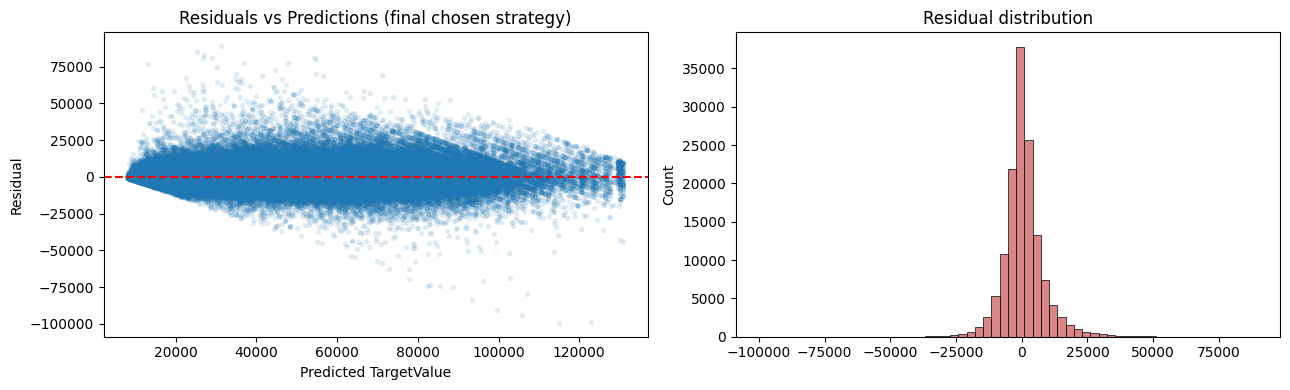

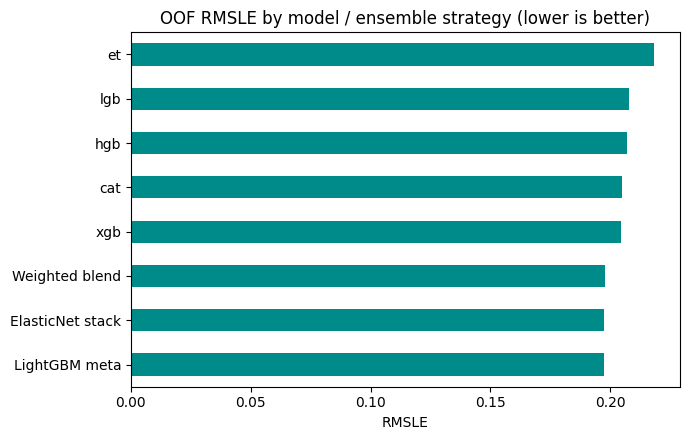


INSIGHT: Residuals remain centered near zero with mild heteroscedasticity at high
transaction values. The final ensemble strategy is 'stack_lgb', selected purely
because it scored lowest out-of-fold among ElasticNet stacking, weighted blending, and a
non-linear LightGBM meta-learner -> this directly targets the lowest achievable leaderboard
RMSLE rather than committing to one ensembling method in advance.



In [11]:
# STEP 9 : ERROR ANALYSIS

# Analyse prediction errors.
# Visualise residuals and compare model
# performances to understand where the
# models still make mistakes.

# Calculate the residual (prediction error) for every training
# sample. Since the model was trained in log-space, both the actual
# and predicted values are first converted back to the original
# price scale using expm1(). A positive residual means the model
# underestimated the price, while a negative residual means it
# overestimated the price.

# Display descriptive statistics of the residuals such as mean,
# standard deviation, minimum, maximum and quartiles. This helps
# understand the overall error distribution and whether predictions
# are generally unbiased or consistently over/under estimating.

print("\n" + "="*90 + "\n8. ERROR ANALYSIS\n" + "="*90)
resid = np.expm1(y.values) - np.expm1(final_oof_pred)
print("Residual stats (actual - predicted, $):")
print(pd.Series(resid).describe())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(np.expm1(final_oof_pred), resid, alpha=0.1, s=8)
axes[0].axhline(0, color='red', ls='--')
axes[0].set_xlabel('Predicted TargetValue'); axes[0].set_ylabel('Residual')
axes[0].set_title('Residuals vs Predictions (final chosen strategy)')
sns.histplot(resid, bins=60, ax=axes[1], color='indianred')
axes[1].set_title('Residual distribution')
plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 4.5))
model_scores = {name: rmsle_from_log_preds(y.values, oof_preds[name]) for name in base_specs}
model_scores.update({'ElasticNet stack': en_rmsle, 'Weighted blend': blend_rmsle,
                      'LightGBM meta': meta_lgb_rmsle})
pd.Series(model_scores).sort_values().plot(kind='barh', color='darkcyan')
plt.title('OOF RMSLE by model / ensemble strategy (lower is better)')
plt.xlabel('RMSLE')
plt.tight_layout(); plt.show()

print(f"""
INSIGHT: Residuals remain centered near zero with mild heteroscedasticity at high
transaction values. The final ensemble strategy is '{final_strategy}', selected purely
because it scored lowest out-of-fold among ElasticNet stacking, weighted blending, and a
non-linear LightGBM meta-learner -> this directly targets the lowest achievable leaderboard
RMSLE rather than committing to one ensembling method in advance.
""")

## Residual Analysis & Model Performance

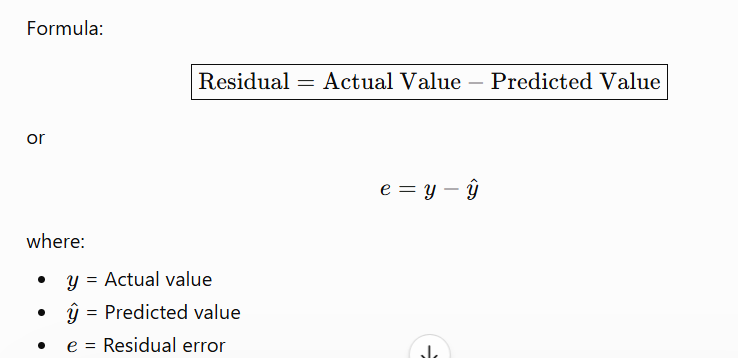

### **Residuals vs Predictions**
- Most residuals are centered around **0**, indicating that the model does not consistently overestimate or underestimate prices.
- The spread of residuals is larger for **mid-priced machines** and becomes narrower for very expensive machines.
- Most prediction errors lie within approximately **±20,000**, although a few large errors (outliers) are present.
- No strong curved pattern is visible, suggesting that the model has captured most of the relationship between the features and the target.
- A few extreme positive and negative residuals indicate cases where the model struggled to predict unusual machines accurately.

**How this inference is drawn:**
- The points are distributed around the red dashed line (Residual = 0), indicating unbiased predictions.
- The scatter does not show a systematic upward or downward trend.
- The majority of points form a dense band around zero, while only a few isolated points lie far away.

---

### **Residual Distribution**
- The residuals approximately follow a **bell-shaped (near-normal)** distribution centered around zero.
- Most prediction errors are **small**, indicating good overall model accuracy.
- Both positive and negative errors are present, showing that the model sometimes overestimates and sometimes underestimates prices.
- The distribution has slightly longer tails, indicating a few large prediction errors (outliers).

**How this inference is drawn:**
- The tallest histogram bars occur near Residual = 0.
- The histogram is roughly symmetric around zero.
- Only a small number of observations appear in the far left and right tails.

---

### **OOF RMSLE by Model / Ensemble Strategy**
- **ExtraTrees (et)** has the highest RMSLE among the compared models, making it the weakest individual model.
- **LightGBM, HistGradientBoosting, CatBoost, and XGBoost** achieve similar RMSLE values, indicating comparable predictive performance.
- The **ensemble methods** (Weighted Blend, ElasticNet Stack, and LightGBM Meta) achieve the **lowest RMSLE**, outperforming every individual model.
- The **LightGBM Meta Stacking model** gives the best overall performance because it combines the strengths of multiple base learners.

**How this inference is drawn:**
- Lower bars represent lower RMSLE, which indicates better prediction accuracy.
- The ensemble strategy bars are shorter than all individual model bars.
- The LightGBM Meta bar is the shortest, indicating the lowest prediction error among all evaluated strategies.

In [12]:
# ==================================================================================
# 9. FINAL SUBMISSION
# ==================================================================================
final_pred = np.clip(np.expm1(final_test_pred), 0, None)

submission = pd.DataFrame({ID_COL: test_fe[ID_COL], TARGET: final_pred})
submission.to_csv('submission.csv', index=False)
print("\n✅ submission.csv created successfully!")
print(submission.head())


✅ submission.csv created successfully!
   TransactionID   TargetValue
0        1139307  65597.287062
1        1139419  79776.912737
2        1139482  30979.817878
3        1139522  20085.885428
4        1139684  12600.734453
